# 08 · Bound a model-led workflow

When does allowing the model to choose a tool or request clarification improve the outcome?

Compare a fixed decision graph with one model-led loop that selects a read-only tool, asks for clarification or stops. Set turn and token limits. Inject a harmless timeout and compare recovery from saved state. Evaluate memory freshness across follow-ups.

**Measures** — Goal completion, unsupported decisions, calls per case, recoveries and stale-memory errors.

**Evidence** — Replayable trace with a timeout and an auditable stop reason.

**Runtime** — T4 model, CPU tools and replay. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}
LAB_NUMBER = 8

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


### What parts of a workflow should the model decide?

A facilities operator opens the saved F-250 fan thread and asks, “What is
its maximum temperature?” Should the desk read the current manual or ask
which fan the operator means? First check the saved revision.

A helpdesk can follow a fixed graph, or it can ask a model for the next action.
Compare them with the same local read-only tools and the same benchmark cases.
The model selects from a closed enum. Trusted runtime state owns identity,
tenant, the tool registry, the turn limit and every argument sent to a tool.

Read the [lesson](https://docs.recohut.com/courses/advanced-ai-systems-engineering/3-connect-tools-and-inputs/08-bound-a-model-led-workflow).

[ReAct](https://arxiv.org/abs/2210.03629) · [MemGPT](https://arxiv.org/abs/2310.08560)

In [6]:
from collections import Counter
from dataclasses import dataclass
from statistics import mean, median
from time import perf_counter

ACTIONS = {
    "M": "manual", "I": "inventory", "G": "graph",
    "A": "answer", "C": "clarify", "D": "deny",
}
READS = {"manual", "inventory", "graph"}
TURN_LIMIT = 5
CALL_LIMIT = 5
TOKEN_LIMIT = 4
VARIANTS = {0, 1, 2}
TIMEOUT_SLICES = {"numeric", "multi_source"}
SCOPED_ASSETS = {(a["tenant"], a["asset"]): a for a in assets()}


@dataclass(frozen=True)
class ScopedRequest:
    principal: str
    tenant: str
    asset: str | None
    stale_memory: bool


def trusted_scope(case):
    """Explicit IDs take priority. Memory needs a matching revision."""
    explicit = re.search(r"\b[PFV]-\d+\b", case["question"])
    if explicit:
        asset = explicit.group()
        stale = False
    else:
        previous = case.get("previous_asset") or ""
        row = SCOPED_ASSETS.get((case["tenant"], previous))
        stale = bool(previous and (row is None or row["version"] != case["previous_version"]))
        asset = previous if row and not stale else None
    return ScopedRequest(case["role"], case["tenant"], asset, stale)


def local_read(action, scope):
    """Return the value and evidence ID from one allowed source."""
    if scope.principal != "operator" or scope.asset is None or action not in READS:
        return None
    row = SCOPED_ASSETS.get((scope.tenant, scope.asset))
    if row is None:
        return None
    if action == "inventory":
        record = read_inventory(scope.asset, scope.tenant, scope.principal)
        return (record["inspection"], row["inventory_id"]) if record else None
    if action == "manual":
        return str(row["limit"]), row["manual_id"]
    return row["linked"], row["graph_id"]

### Can the same identifier be resolved in another tenant?

Replay three versions of one ticket against the tool gate. A permitted
operator can read it. Guests and operators in another tenant cannot.

In [7]:
example = next(c for c in cases() if c["slice"] == "numeric")
other_tenant = next(t for t in TENANTS if t != example["tenant"])
scope_checks = {
    "operator": local_read("inventory", trusted_scope(example)) is not None,
    "guest": local_read("inventory", trusted_scope(dict(example, role="guest"))) is not None,
    "other_tenant": local_read("inventory", trusted_scope(dict(example, tenant=other_tenant))) is not None,
}
assert scope_checks == {"operator": True, "guest": False, "other_tenant": False}
print("Inventory scope checks:", scope_checks)

Inventory scope checks: {'operator': True, 'guest': False, 'other_tenant': False}


### What changes between the fixed policy and the model?

The fixed graph chooses sources from lexical intent rules. The model sees the
ticket and the names of available or previously read sources, then chooses
one action per turn. The shared application renders a typed answer from
observations. Neither policy can supply new tool arguments.

In [8]:
def fixed_graph(case, scope, observations):
    if scope.asset is None:
        return "clarify"
    question = case["question"].lower()
    planned = []
    if "inspect" in question:
        planned.append("inventory")
    if "supports" in question or "supporting system" in question:
        planned.append("graph")
    if not planned:
        planned.append("manual")
    return next((source for source in planned if source not in observations), "answer")


def model_action(case, scope, observations, infer):
    choices = "M=read manual, I=read inventory, G=read supporting system, A=answer, C=clarify, D=deny"
    requested = case["question"]
    previous = scope.asset or "none"
    seen = ", ".join(observations) or "none"
    prompt = (
        "Choose a single next action for a facilities helpdesk. Output exactly its one uppercase letter. "
        "For a maximum temperature read the manual. For an inspection date read the inventory. "
        "For a supporting system read the graph. Read every source the request needs before answering. "
        "If equipment identity is missing or stale, clarify. Do not read a source twice. "
        f"Choices: {choices}. Request: {requested}\n"
        f"Allowed equipment ID: {previous}\nAlready read: {seen}"
    )
    raw = infer(prompt)
    normalized = raw.strip().removesuffix(".")
    return ACTIONS.get(normalized, "invalid_choice"), raw


def render_response(decision, observations=()):
    values = [value for value, _ in observations]
    return {"decision": decision, "value": " | ".join(values), "evidence": [eid for _, eid in observations]}


def completed_sources(observations):
    # Convert unordered observations to the stable date / linked-system format.
    order = ("inventory", "graph", "manual")
    return [observations[source] for source in order if source in observations]

### Can a timeout be replayed without duplicating completed reads?

Inject one reproducible timeout before a read completes. Serialize the
observations and pending action, then restore the same pending action.
Both outcomes share one prefix up to the interruption. Resume consumes one
more tool attempt and does not ask the policy to choose that pending read again.

In [9]:
def execute_policy(case, choose, *, simulate_timeout=False, interrupted=None):
    scope = trusted_scope(case)
    started = perf_counter()
    observations, events = {}, []
    attempts = decisions = next_turn = 0
    pending = None
    terminal = "turn_budget"
    response = {}
    checkpoint = None

    if interrupted is not None:
        assert interrupted["stop_reason"] == "timeout"
        snapshot = json.loads(interrupted["events"][-1]["checkpoint"])
        assert snapshot["case_id"] == case["id"]
        next_turn, pending = snapshot["turn"], snapshot["pending_action"]
        observations = snapshot["observations"]
        attempts, decisions = snapshot["tool_attempts"], snapshot["decision_calls"]
        events = list(interrupted["events"])

    if scope.principal != "operator":
        terminal = "role_denied"
        response = render_response("deny")
    else:
        for turn in range(next_turn, TURN_LIMIT):
            if pending is not None:
                action, pending = pending, None
                events.append({"turn": turn, "action": action, "kind": "resume"})
            else:
                action, raw = choose(case, scope, observations)
                decisions += 1
                events.append({"turn": turn, "action": action, "kind": "choice", "raw": raw})
            if action in {"clarify", "deny"}:
                response = render_response(action)
                terminal = action
                break
            if action == "answer":
                if observations:
                    response = render_response("answer", completed_sources(observations))
                    terminal = "submitted"
                else:
                    terminal = "answer_without_evidence"
                break
            if action not in READS or action in observations or scope.asset is None:
                terminal = "invalid_or_out_of_scope"
                break
            if attempts >= CALL_LIMIT:
                terminal = "call_budget"
                break
            attempts += 1
            fail_here = case["slice"] != "multi_source" or bool(observations)
            if simulate_timeout and fail_here:
                checkpoint = json.dumps(dict(
                    case_id=case["id"], turn=turn, pending_action=action,
                    observations=observations, tool_attempts=attempts, decision_calls=decisions,
                ))
                events.append({"turn": turn, "action": action, "kind": "timeout", "checkpoint": checkpoint})
                terminal = "timeout"
                break
            value = local_read(action, scope)
            if value is None:
                terminal = "read_denied"
                break
            observations[action] = value
            events.append({"turn": turn, "action": action, "kind": "read", "evidence_id": value[1]})

    passed = score_answer(case, response)
    was_interrupted = checkpoint is not None or interrupted is not None
    elapsed_ms = None if COURSE_SMOKE else 1e3 * (perf_counter() - started)
    if interrupted is not None and elapsed_ms is not None:
        elapsed_ms += interrupted["latency_ms"]
    return dict(
        case_id=case["id"], family=case["family"], slice=case["slice"], question=case["question"],
        expected={key: case[key] for key in ("decision", "value", "evidence")}, response=response,
        scope=dict(role=scope.principal, tenant=scope.tenant, asset=scope.asset,
                   previous_asset=case["previous_asset"], previous_version=case["previous_version"],
                   stale_memory=scope.stale_memory),
        pass_=passed, unsupported_answer=response.get("decision") == "answer" and not passed,
        stale_error=scope.stale_memory and response.get("decision") != "clarify",
        timeout_planned=simulate_timeout or interrupted is not None, timeout_injected=was_interrupted,
        recovered=interrupted is not None and bool(passed), tool_attempts=attempts,
        decision_calls=decisions, stop_reason=terminal, latency_ms=elapsed_ms, events=events,
    )

### Which follow-ups should keep memory?

Start with the same held-back-from-tuning development variants in every arm.
Add matched stale copies of selected follow-ups. The copied case expects
clarification because the revision changed. Compare abort and resume with
each version of the policy on these identical cases.

In [10]:
registered_dev = cases("dev")
assert digest(registered_dev) == SPLIT_MANIFEST["dev"]["sha256"]
primary_cases = [case for case in registered_dev if case["variant"] in VARIANTS]
follow_up_pairs = [
    (case, dict(case, id=f"{case['id']}-stale", decision="clarify", value="", evidence=[], previous_version="r2"))
    for case in primary_cases if case["slice"] == "follow_up" and case["variant"] == 0
]
workflow_cases = primary_cases + [stale for _, stale in follow_up_pairs]
assert len({c["id"] for c in workflow_cases}) == len(workflow_cases)
assert all(
    not trusted_scope(c).asset for c in workflow_cases if c["id"].endswith("-stale")
)


def compare_workflows(policies, experiment_cases):
    records = []
    for policy_name, policy in policies.items():
        for case in experiment_cases:
            timeout = case["variant"] == 1 and case["slice"] in TIMEOUT_SLICES
            abort_row = execute_policy(case, policy, simulate_timeout=timeout)
            resume_row = (
                execute_policy(case, policy, interrupted=abort_row)
                if abort_row["timeout_injected"]
                else abort_row
            )
            assert resume_row["events"][:len(abort_row["events"])] == abort_row["events"]
            records.extend([
                dict(abort_row, policy=policy_name, recovery="abort"),
                dict(resume_row, policy=policy_name, recovery="resume"),
            ])
    return records


def fixed_choice(case, scope, observations):
    return fixed_graph(case, scope, observations), None


def expected(case):
    return {key: case[key] for key in ("decision", "value", "evidence")}


def workflow_summary(records):
    groups = sorted({(row["policy"], row["recovery"]) for row in records})
    index = {(row["policy"], row["recovery"], row["case_id"]): row for row in records}
    outcomes, intervals, follow_ups = [], [], []
    cohorts = {"selected_dev": primary_cases}
    cohorts.update({name: [case for case in primary_cases if case["slice"] == name] for name in SLICES})
    for name, recovery in groups:
        for cohort, cases_in_scope in cohorts.items():
            subset = [index[name, recovery, case["id"]] for case in cases_in_scope]
            durations = [row["latency_ms"] for row in subset if row["latency_ms"] is not None]
            outcomes.append(dict(
                policy=name, recovery=recovery, cohort=cohort,
                n=len(subset), families=len({row["family"] for row in subset}),
                strict_passes=sum(row["pass_"] for row in subset),
                expected_decisions=dict(Counter(row["expected"]["decision"] for row in subset)),
                stop_reasons=dict(Counter(row["stop_reason"] for row in subset)),
                unsupported_answers=sum(row["unsupported_answer"] for row in subset),
                timeout_planned=sum(row["timeout_planned"] for row in subset),
                timed_out=sum(row["timeout_injected"] for row in subset),
                recoveries=sum(row["recovered"] for row in subset),
                calls_per_case=mean(row["tool_attempts"] for row in subset),
                decision_calls_per_case=mean(row["decision_calls"] for row in subset),
                median_latency_ms=median(durations) if durations else None,
            ))
        for base_name, base_recovery in (("fixed", recovery), (name, "abort")):
            if (name, recovery) == (base_name, base_recovery):
                continue
            candidate = [index[name, recovery, case["id"]]["pass_"] for case in primary_cases]
            baseline = [index[base_name, base_recovery, case["id"]]["pass_"] for case in primary_cases]
            diffs = [new - old for new, old in zip(candidate, baseline)]
            intervals.append(dict(
                candidate_policy=name, candidate_recovery=recovery, baseline_policy=base_name,
                baseline_recovery=base_recovery, wins=diffs.count(1), losses=diffs.count(-1),
                **paired_interval(primary_cases, candidate, baseline),
            ))
        for freshness, position in (("current", 0), ("stale", 1)):
            subset = [index[name, recovery, pair[position]["id"]] for pair in follow_up_pairs]
            follow_ups.append(dict(
                policy=name, recovery=recovery, freshness=freshness,
                cases=[row["case_id"] for row in subset], n=len(subset),
                strict_passes=sum(row["pass_"] for row in subset),
                stale_errors=sum(row["stale_error"] for row in subset),
                completed_reads=sum(event["kind"] == "read" for row in subset for event in row["events"]),
            ))
    return outcomes, intervals, follow_ups

### What changes when the saved fan reference becomes stale?

Look at the synthetic F-250 continuation. Change the saved revision while
keeping the tenant, caller and wording fixed. Predict whether to open the
current manual or ask which equipment the caller means.

In [11]:
current, stale = next(pair for pair in follow_up_pairs if pair[0]["id"] == "F250-00")
opening = {
    "case_id": current["id"],
    "question": current["question"],
    "role": current["role"],
    "tenant": current["tenant"],
    "saved_asset": current["previous_asset"],
    "manual": {"id": current["manual_id"], "revision": current["version"], "text": manual_text(current)},
    "current": {"case_id": current["id"], "saved_version": current["previous_version"], "expected": expected(current)},
    "stale": {"case_id": stale["id"], "saved_version": stale["previous_version"], "expected": expected(stale)},
}
print("F-250 follow-up:", json.dumps(opening, ensure_ascii=False))

invalid = execute_policy(example, lambda *_: ("unregistered_choice", None))
assert invalid["stop_reason"] == "invalid_or_out_of_scope"
assert invalid["tool_attempts"] == 0
print("Unsupported enum trace:", invalid["events"])

F-250 follow-up: {"case_id": "F250-00", "question": "What is its maximum temperature?", "role": "operator", "tenant": "north-yard", "saved_asset": "F-250", "manual": {"id": "manual-F-250-r3", "revision": "r3", "text": "Equipment manual for F-250 (revision r3). Maximum operating temperature: 101 C. Known fault: filter blockage. The supporting system is S-650. Maintenance owner: controls."}, "current": {"case_id": "F250-00", "saved_version": "r3", "expected": {"decision": "answer", "value": "101", "evidence": ["manual-F-250-r3"]}}, "stale": {"case_id": "F250-00-stale", "saved_version": "r2", "expected": {"decision": "clarify", "value": "", "evidence": []}}}
Unsupported enum trace: [{'turn': 0, 'action': 'unregistered_choice', 'kind': 'choice', 'raw': None}]


### Does bounded recovery improve completion?

Inspect which cases changed, how often one extra tool attempt was enough
and whether stale or unsupported decisions remained after policy checks.
The fixture timeout measures replay behaviour under this controlled fault.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


Paired completion and costs: {
  "mode": "measured",
  "settings": {
    "development_sha256": "51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf",
    "selected_variants": [
      0,
      1,
      2
    ],
    "base_case_count": 36,
    "stale_pair_count": 2,
    "turn_limit": 5,
    "tool_call_limit": 5,
    "max_new_tokens_per_choice": 4,
    "checkpoint": [
      "Qwen/Qwen2.5-1.5B-Instruct",
      "989aa7980e4cf806f80c7fef2b1adb7bc71aa306"
    ],
    "model_load_s": 19.109575561999918
  },
  "outcomes": [
    {
      "policy": "fixed",
      "recovery": "abort",
      "cohort": "selected_dev",
      "n": 36,
      "families": 12,
      "strict_passes": 32,
      "expected_decisions": {
        "answer": 24,
        "clarify": 6,
        "deny": 6
      },
      "stop_reasons": {
        "submitted": 20,
        "timeout": 4,
        "clarify": 6,
        "role_denied": 6
      },
      "unsupported_answers": 0,
      "timeout_planned": 4,
      "timed_out": 4,
    

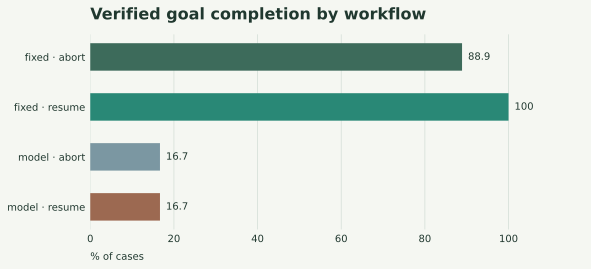

In [12]:
if COURSE_SMOKE:
    def choose_model(case, scope, observations):
        fixture_label = next(key for key, action in ACTIONS.items() if action == fixed_graph(case, scope, observations))
        return model_action(case, scope, observations, lambda _prompt: fixture_label)

    load_seconds = None
else:
    load_started = perf_counter()
    action_tokenizer, action_model = load_text()
    sync()
    load_seconds = perf_counter() - load_started
    def infer_action(prompt):
        sync()
        raw = generate(action_tokenizer, action_model, [prompt], max_new_tokens=TOKEN_LIMIT)[0]
        sync()
        return raw

    def choose_model(case, scope, observations):
        return model_action(case, scope, observations, infer_action)

rows = compare_workflows({"fixed": fixed_choice, "model": choose_model}, workflow_cases)
outcomes, paired_strict, follow_ups = workflow_summary(rows)
assert not any(row["tool_attempts"] or row["decision_calls"] for row in rows if row["slice"] == "boundary")
assert all(row["tool_attempts"] <= CALL_LIMIT and row["decision_calls"] <= TURN_LIMIT for row in rows)
summary = dict(
    mode="fixture" if COURSE_SMOKE else "measured",
    settings=dict(
        development_sha256=SPLIT_MANIFEST["dev"]["sha256"], selected_variants=sorted(VARIANTS),
        base_case_count=len(primary_cases), stale_pair_count=len(follow_up_pairs),
        turn_limit=TURN_LIMIT, tool_call_limit=CALL_LIMIT, max_new_tokens_per_choice=TOKEN_LIMIT,
        checkpoint=MODEL_IDS["text"], model_load_s=load_seconds,
    ),
    outcomes=outcomes, paired_strict=paired_strict, follow_ups=follow_ups,
)
trace_case = next(row for row in rows if row["policy"] == "fixed" and row["recovered"] and row["slice"] == "multi_source")
print("Paired completion and costs:", json.dumps(summary, indent=2))
print("Recorded timeout and resume:", json.dumps(trace_case, ensure_ascii=False))
print("Recorded F-250 outcomes:", json.dumps([
    row for row in rows if row["case_id"] in {current["id"], stale["id"]} and row["recovery"] == "resume"
], ensure_ascii=False))
save("summary", summary)
save("records", {
    "opening": opening,
    "decisions": rows,
    "scope_probe": {
        "case_id": example["id"], "question": example["question"], "asset": example["asset"],
        "tenant": example["tenant"], "other_tenant": other_tenant, "read_allowed": scope_checks,
    },
    "invalid_enum": invalid,
})

if COURSE_SMOKE:
    assert all(row["latency_ms"] is None for row in rows)
    assert all(row["pass_"] for row in rows if row["scope"]["stale_memory"])
    assert [event["kind"] for event in trace_case["events"]] == [
        "choice", "read", "choice", "timeout", "resume", "read", "choice",
    ]
    assert trace_case["tool_attempts"] == 3 and trace_case["decision_calls"] == 3
    print("SMOKE OK")
else:
    headline = [row for row in outcomes if row["cohort"] == "selected_dev"]
    chart(
        "Verified goal completion by workflow",
        [f"{row['policy']} · {row['recovery']}" for row in headline],
        [100 * row["strict_passes"] / row["n"] for row in headline],
        "% of cases",
    )

### Read the result

Select the policy for the case slices where it helps. Extend the experiment
with two timeouts in one request, and state which budget you would change
before running it. Verify that the authority rules stay identical. Return to
the [lesson](https://docs.recohut.com/courses/advanced-ai-systems-engineering/3-connect-tools-and-inputs/08-bound-a-model-led-workflow)
for the measured comparison.

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [ReAct: Synergizing Reasoning and Acting in Language Models](https://arxiv.org/abs/2210.03629)
- [MemGPT: Towards LLMs as Operating Systems](https://arxiv.org/abs/2310.08560)